# Task 4 – Classification: LogisticRegression vs DecisionTreeClassifier
Dự đoán **sentiment_clean** (Positive / Neutral / Negative) từ nội dung đánh giá sản phẩm.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

df = pd.read_json("clean_data.json")

# Tạo nhãn từ rating_num (cột số đã sạch) để tránh lỗi rating dạng "** 2/5"
df["sentiment_clean"] = pd.cut(
    df["rating_num"],
    bins=[0, 2, 3, 5],
    labels=["Negative", "Neutral", "Positive"]
).astype(str)

# Bỏ cột rating để tránh leakage
df = df.drop(columns=["rating", "rating_num", "sentiment"])
TARGET = "sentiment_clean"

counts = df[TARGET].value_counts()
print(counts)
print(f"Tỷ lệ lớn/nhỏ = {counts.max() / counts.min():.2f}")

sentiment_clean
Negative    140
Positive    124
Neutral      72
Name: count, dtype: int64
Tỷ lệ lớn/nhỏ = 1.94


## 1. Chia dữ liệu và tạo feature từ review

In [2]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42,
                                     stratify=df[TARGET])

tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["generated_review"])
X_test = tfidf.transform(test_df["generated_review"])
y_train, y_test = train_df[TARGET], test_df[TARGET]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (268, 5757)  Test: (68, 5757)


## 2. Huấn luyện, đánh giá và confusion matrix

LogisticRegression
              precision    recall  f1-score   support

    Negative      1.000     1.000     1.000        28
     Neutral      0.923     0.800     0.857        15
    Positive      0.889     0.960     0.923        25

    accuracy                          0.941        68
   macro avg      0.937     0.920     0.927        68
weighted avg      0.942     0.941     0.940        68

DecisionTreeClassifier
              precision    recall  f1-score   support

    Negative      0.821     0.821     0.821        28
     Neutral      0.526     0.667     0.588        15
    Positive      1.000     0.840     0.913        25

    accuracy                          0.794        68
   macro avg      0.783     0.776     0.774        68
weighted avg      0.822     0.794     0.804        68



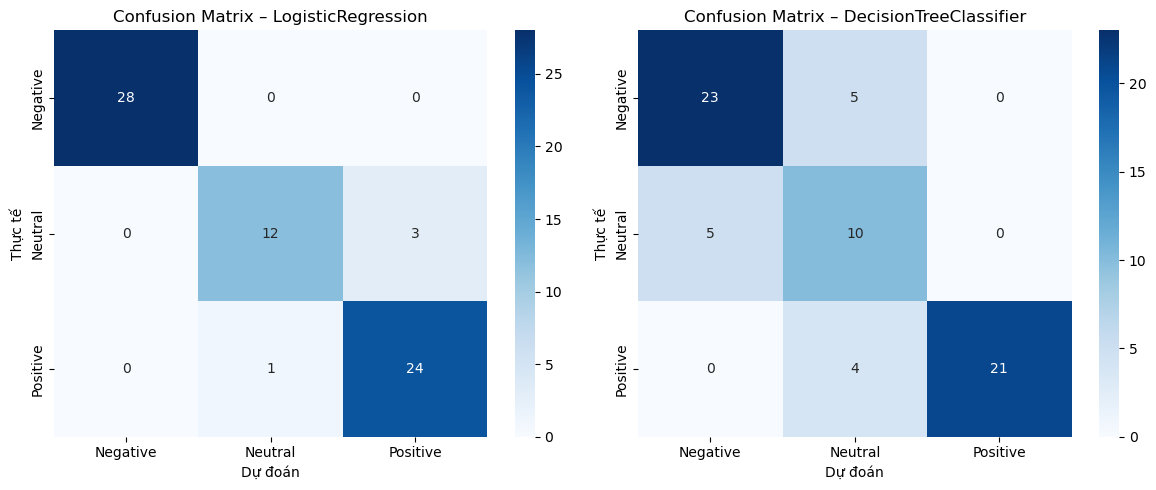

In [3]:
models = {
    "LogisticRegression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    "DecisionTreeClassifier": DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=42),
}

scores = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = sorted(y_test.unique())

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores[name] = f1_score(y_test, y_pred, average="macro")

    print("=" * 60, f"\n{name}\n", "=" * 60)
    print(classification_report(y_test, y_pred, digits=3))

    sns.heatmap(confusion_matrix(y_test, y_pred, labels=labels), annot=True, fmt="d",
                cmap="Blues", ax=ax, xticklabels=labels, yticklabels=labels)
    ax.set_title(f"Confusion Matrix – {name}")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")

plt.tight_layout(); plt.show()

## 3. So sánh và chọn mô hình

In [4]:
best = max(scores, key=scores.get)
print({k: round(v, 3) for k, v in scores.items()})
print(f"Mô hình tốt nhất theo F1 (macro): {best}")

{'LogisticRegression': 0.927, 'DecisionTreeClassifier': 0.774}
Mô hình tốt nhất theo F1 (macro): LogisticRegression


## 4. Nhận xét
- So sánh Macro F1 in ra ở mục 3 để xác định mô hình tốt hơn trên dữ liệu hiện tại.
- Nhãn cảm xúc được tạo từ `rating_num`, nhưng **chỉ nội dung review** được đưa vào TF-IDF làm đầu vào.
- Kết quả trên tập nhỏ có thể thay đổi khi dữ liệu hoặc cách chia train/test thay đổi.


## 5. Lưu mô hình cho Task 5 – Streamlit
Chạy cell sau khi huấn luyện để xuất các mô hình và TF-IDF.


In [6]:
from pathlib import Path
from joblib import dump
output_dir = Path("Task5_Streamlit/artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
dump(tfidf, output_dir / "task4_tfidf.joblib")
for name, model in models.items():
    dump(model, output_dir / f"task4_{name}.joblib")
pd.DataFrame([{"Model": name, "F1_macro": score} for name, score in scores.items()]).to_csv(
    output_dir / "task4_metrics.csv", index=False, encoding="utf-8-sig"
)
